# 다형성 (Polymorphism) — 하나의 명령, 여러 결과
### 캠퍼스몰 상품 시스템 리팩터링 프로젝트 

## 오늘의 이야기

> 온라인 쇼핑몰 **캠퍼스몰**에 입사한 지 일주일 된 신입 백엔드 개발자 **민준**.
> 팀장님이 첫 업무를 줍니다.
>
> *"장바구니 금액 계산 코드 좀 맡아줘. 상품 종류가 계속 늘어날 거야."*
>
> 열어 본 코드는 `if / elif` 가 끝없이 이어지는 거대한 함수였습니다.
> 민준은 5단계에 걸쳐 이 코드를 **새 상품이 들어와도 고칠 곳이 없는 코드**로 바꿔 나갑니다.

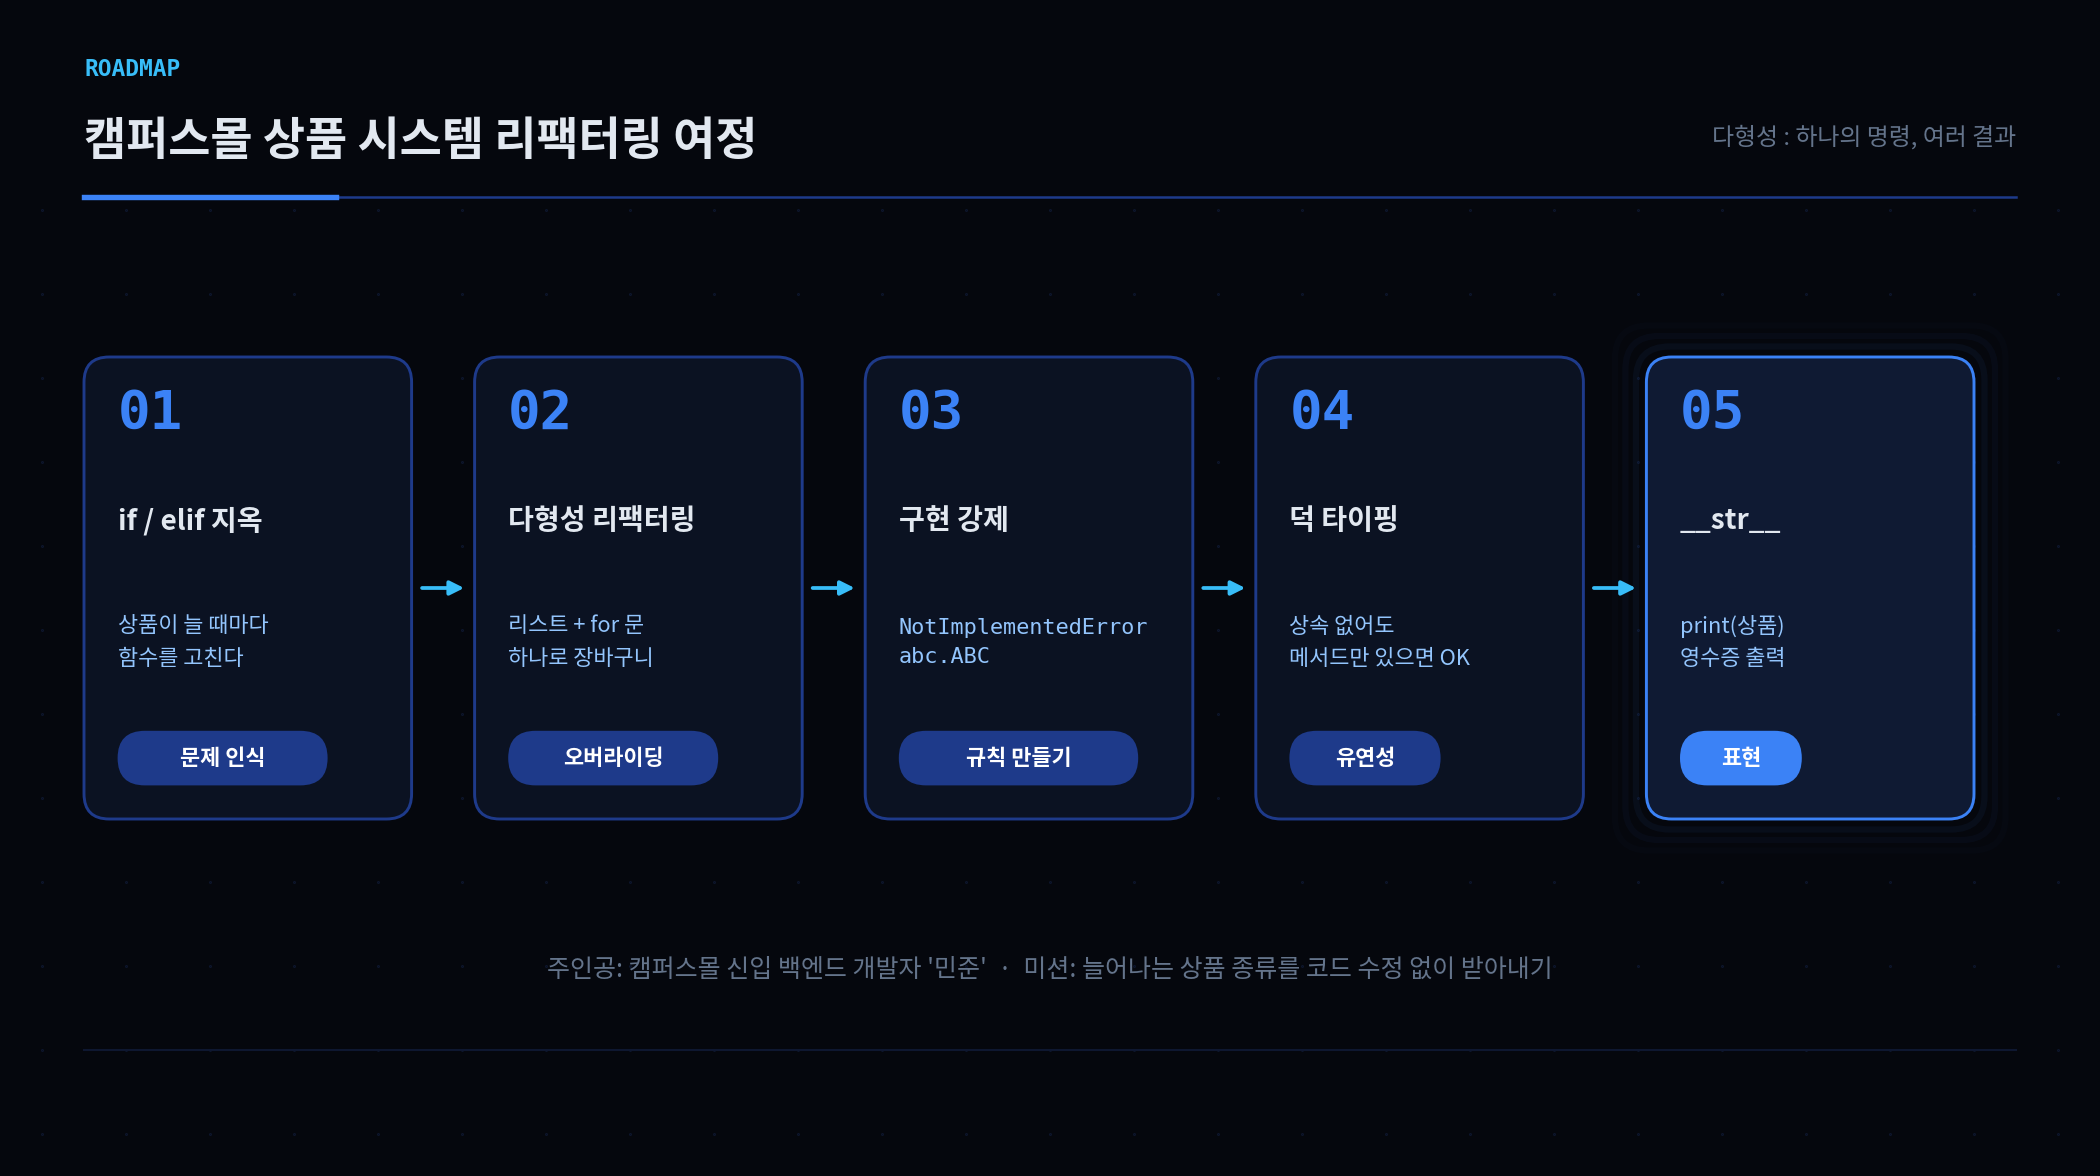

| 단계 | 민준이 겪는 상황 | 배우는 개념 |
|---|---|---|
| STEP 1 | 도서 카테고리 추가 요청 → if 함수 여러 곳 수정 | 다형성의 필요성, "하나의 명령, 여러 결과" |
| STEP 2 | 상품을 클래스로 바꾸고 장바구니를 for 하나로 | 오버라이딩, 리스트 + for 문 |
| STEP 3 | 동료가 가구 클래스에서 메서드를 깜빡 → 잘못된 결제 | `NotImplementedError`, `abc` |
| STEP 4 | 외부 파트너사의 기프트카드를 장바구니에 넣어야 함 | 덕 타이핑 |
| STEP 5 | 영수증에 `<object at 0x...>` 가 찍힘 | `__str__` |
| 미션 | 주문 영수증 시스템 완성 | 전체 통합 |

### 캠퍼스몰 가격 규칙 

| 상품 종류 | 최종 가격 계산 | 배송 방법 |
|---|---|---|
| 전자제품 | 정가 + 연장 보증료 5% | 설치 기사 방문 |
| 의류 | 정가 × 0.8 (시즌 세일 20%) | 일반 택배 |
| 식품 | 정가 + 냉장 배송비 3,000원 | 새벽 냉장 배송 |
| 도서 *(STEP 1에서 추가)* | 정가 × 0.9 (10% 할인) | 무료 배송 |
| 가구 *(STEP 3에서 추가)* | 정가 + 설치비 50,000원 | 2인 설치 배송 |

> 소수점 오차를 피하기 위해 퍼센트 계산은 `price * 105 // 100` 처럼 **정수 연산**으로 합니다.

---
# STEP 1 · if / elif 지옥

> 민준이 물려받은 코드입니다. 상품 종류(`kind`)를 문자열로 받아서 **if / elif 로 하나하나 물어보고** 계산합니다.
> 가격 계산 함수와 배송 안내 함수, 두 곳에 똑같은 분기가 있습니다.

In [ ]:
# 민준이 물려받은 레거시 코드
def calc_price(kind, price):
    if kind == "전자제품":
        return price + price * 5 // 100      # 보증료 5%
    elif kind == "의류":
        return price * 80 // 100             # 20% 세일
    elif kind == "식품":
        return price + 3000                  # 냉장 배송비
    else:
        raise ValueError(f"알 수 없는 상품 종류: {kind}")


def shipping_info(kind):
    if kind == "전자제품":
        return "설치 기사 방문"
    elif kind == "의류":
        return "일반 택배"
    elif kind == "식품":
        return "새벽 냉장 배송"
    else:
        raise ValueError(f"알 수 없는 상품 종류: {kind}")


# 장바구니: (종류, 상품명, 정가) 튜플의 리스트
cart = [
    ("전자제품", "노트북", 1_200_000),
    ("의류", "후드티", 89_000),
    ("식품", "감귤박스", 25_000),
]

total = 0
for kind, name, price in cart:
    p = calc_price(kind, price)
    total += p
    print(f"{name:6} {p:>10,}원  | {shipping_info(kind)}")
print(f"합계: {total:,}원")

### 팀장님의 새 요청: "다음 주부터 **도서**도 팔아요."

도서를 추가하려면 민준은 무엇을 해야 할까요?

1. `calc_price` 에 `elif kind == "도서":` 추가
2. `shipping_info` 에 `elif kind == "도서":` 추가
3. 혹시 다른 파일에도 `if kind == ...` 가 있나? **전부 찾아서 수정**
4. 한 곳이라도 빠뜨리면 → `ValueError` 또는 잘못된 계산

**상품 종류 1개 추가 = 분기 N곳 수정.** 상품이 50종이 되면 함수 하나가 수백 줄이 됩니다.

### 해결의 실마리: "하나의 명령, 여러 결과"

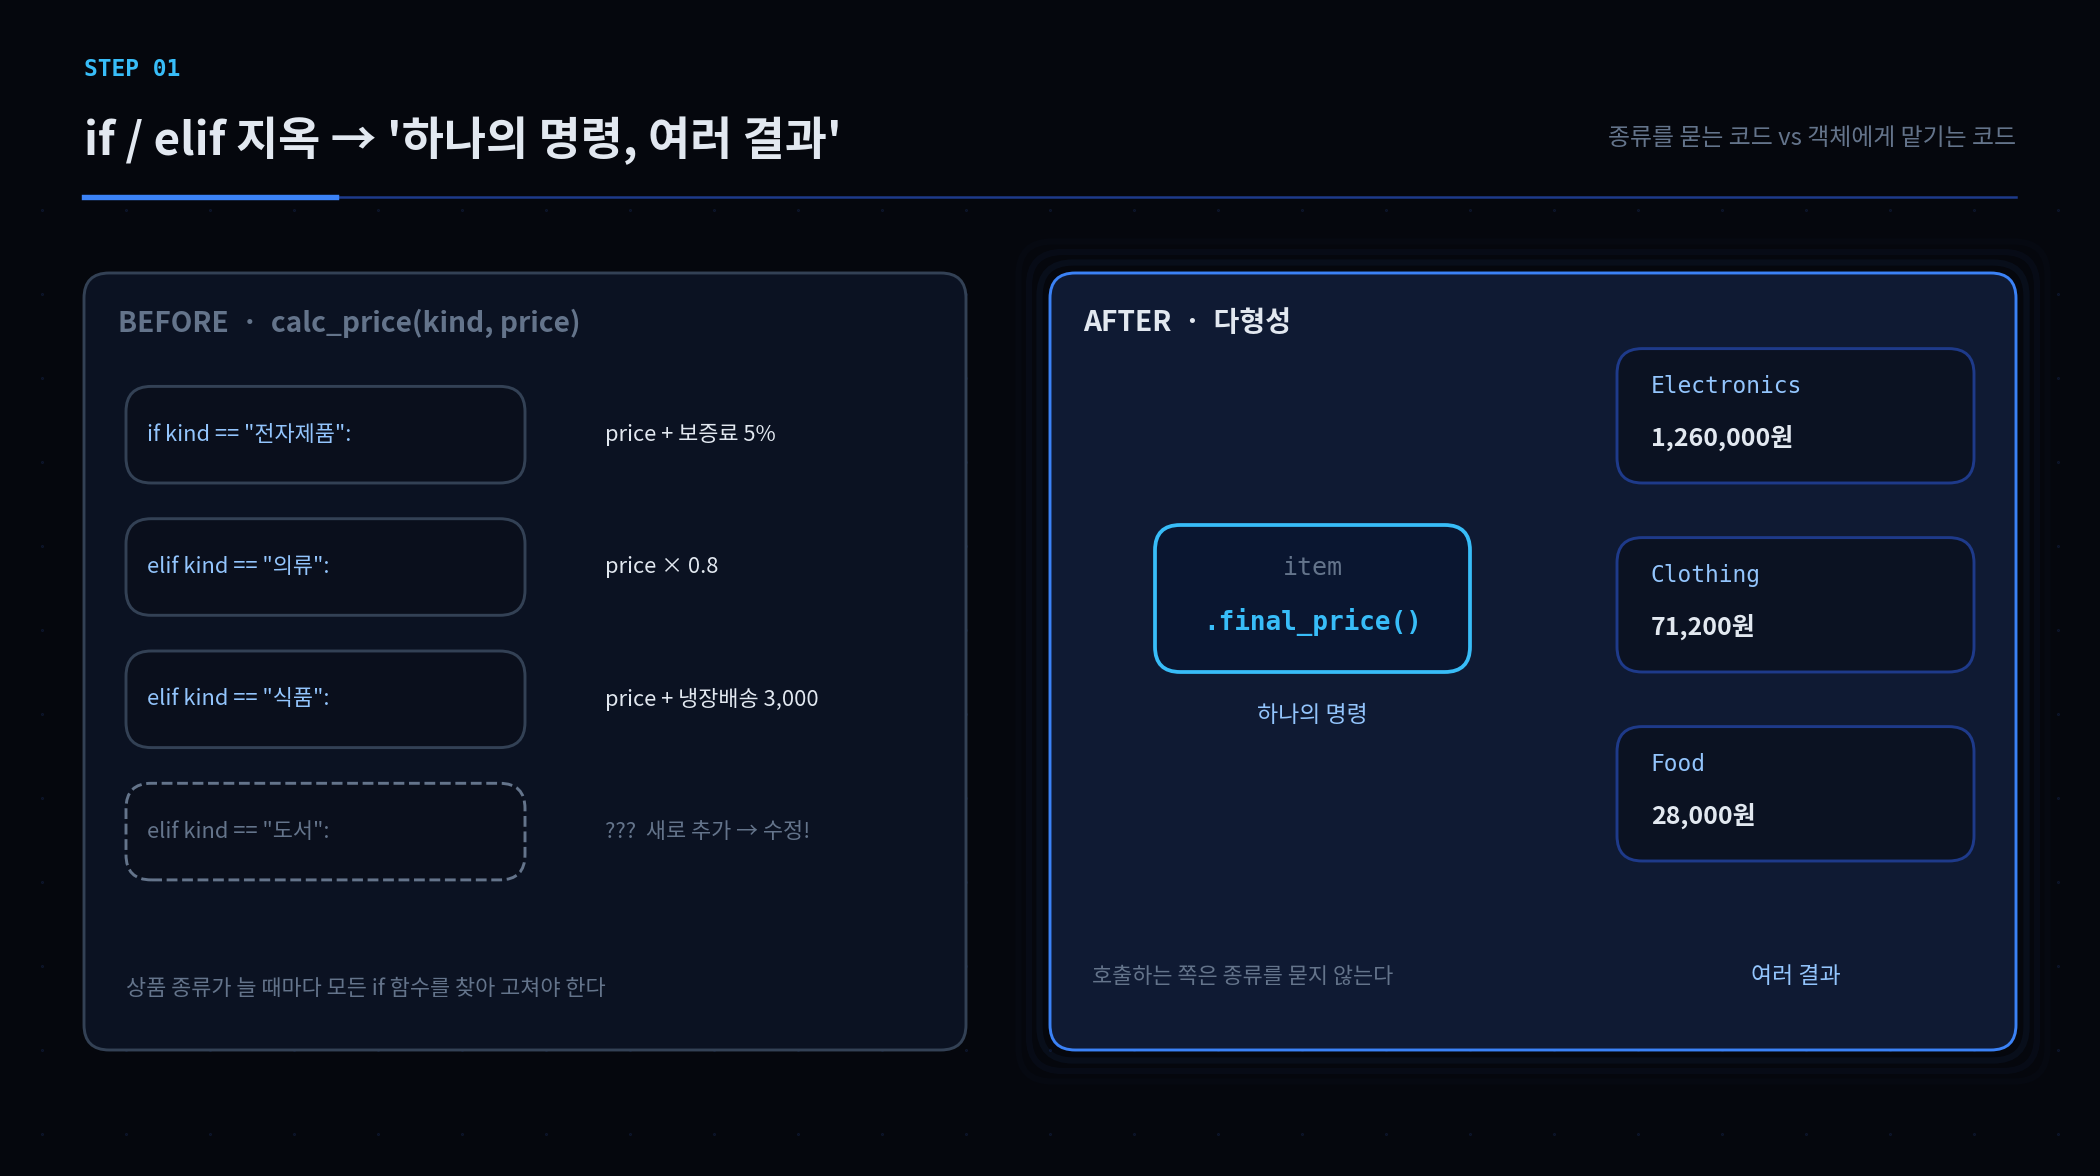

- **if / elif 방식**: 호출하는 쪽이 "너 무슨 종류야?" 하고 **물어본 뒤** 직접 계산합니다.
- **다형성 방식**: 호출하는 쪽은 `item.final_price()` 라는 **똑같은 명령 하나**만 내립니다.
  각 객체가 **자기 방식대로** 계산해서 서로 다른 결과를 돌려줍니다.

> **다형성(Polymorphism)** = poly(여러) + morph(형태).
> 같은 이름의 메서드 호출이 **객체의 종류에 따라 다르게 동작**하는 성질입니다.

생활 속 예: 매장 직원이 "**계산해 주세요**" 라고 말하면 → 카드 단말기는 카드 결제, 현금함은 거스름돈 계산, 상품권 리더기는 잔액 차감.
명령은 하나, 결과는 여러 가지입니다.

### 사실 우리는 이미 다형성을 쓰고 있었다

파이썬 내장 함수 `len()` 과 연산자 `+` 도 대상에 따라 다르게 동작합니다.

In [ ]:
print(len("캠퍼스몰"))          # 문자열 → 글자 수
print(len([1, 2, 3]))           # 리스트 → 원소 수
print(len({"a": 1, "b": 2}))    # 딕셔너리 → 키 개수

print(3 + 4)                    # 숫자 → 덧셈
print("캠퍼스" + "몰")           # 문자열 → 이어 붙이기
print([1, 2] + [3])             # 리스트 → 합치기

## 실습 1-1 · 레거시 코드에 도서 추가해 보기 (고통 체험)

아래 셀에서 `calc_price_v2`, `shipping_info_v2` 에 **도서** 분기를 추가하세요.
- 도서: 정가 × 0.9 (`price * 90 // 100`), 배송은 `"무료 배송"`

작업하면서 **몇 군데를 고쳤는지** 세어 보세요.

In [ ]:
def calc_price_v2(kind, price):
    if kind == "전자제품":
        return price + price * 5 // 100
    elif kind == "의류":
        return price * 80 // 100
    elif kind == "식품":
        return price + 3000
    # TODO: 도서 분기 추가
    else:
        raise ValueError(f"알 수 없는 상품 종류: {kind}")


def shipping_info_v2(kind):
    if kind == "전자제품":
        return "설치 기사 방문"
    elif kind == "의류":
        return "일반 택배"
    elif kind == "식품":
        return "새벽 냉장 배송"
    # TODO: 도서 분기 추가
    else:
        raise ValueError(f"알 수 없는 상품 종류: {kind}")

In [ ]:
# 확인 셀
assert calc_price_v2("도서", 30_000) == 27_000
assert shipping_info_v2("도서") == "무료 배송"
print("실습 1-1 통과! 몇 군데를 고쳤나요?")

## 실습 1-2 · 생각해 보기

아래 질문에 대한 답을 마크다운 셀에 적어 보세요.

1. 상품 종류가 30개, 분기 함수가 5개라면 `elif` 는 총 몇 개일까요?
2. 새 종류를 추가할 때 **한 곳만 빠뜨리면** 어떤 일이 생길까요?
3. "하나의 명령, 여러 결과"의 생활 속 예를 하나 들어 보세요.

*(여기에 답을 적어 보세요)*

---
# STEP 2 · 다형성 리팩터링 — 리스트 하나, for 문 하나

> 민준은 결심합니다. *"종류를 묻지 말고, 상품에게 직접 계산하라고 시키자."*
>
> 1. 부모 클래스 `Product` 가 **약속**을 정합니다: 모든 상품은 `final_price()` 와 `shipping_info()` 를 가진다.
> 2. 자식 클래스가 그 메서드를 **자기 방식대로 오버라이딩**합니다.
> 3. 장바구니는 **객체들의 리스트**가 되고, for 문은 종류를 묻지 않습니다.

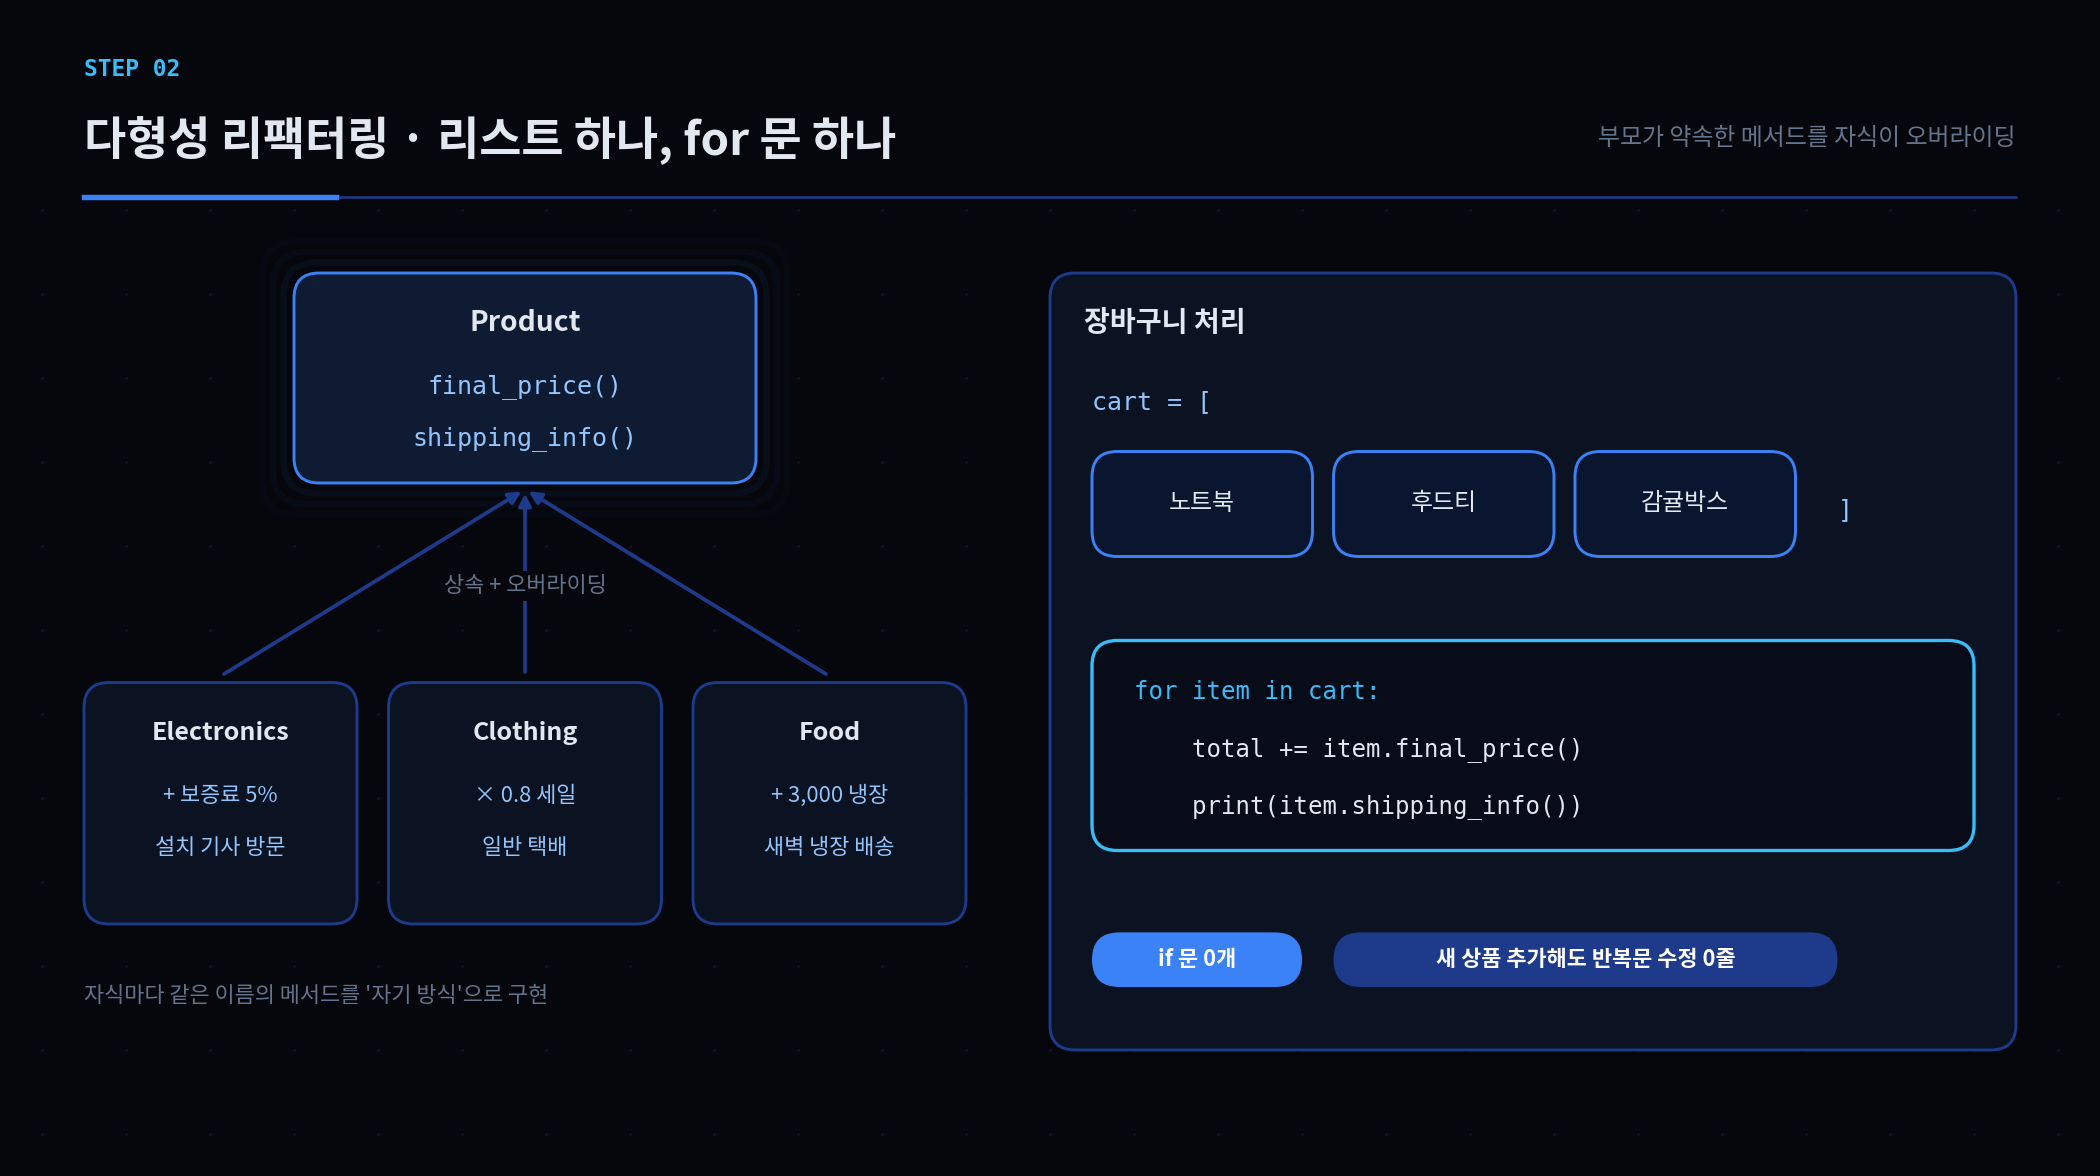

In [ ]:
class Product:
    """모든 상품의 부모 클래스 (아직은 기본 구현이 들어 있음)"""
    category = "기타"

    def __init__(self, name, price):
        self.name = name
        self.price = price

    def final_price(self):
        return self.price

    def shipping_info(self):
        return "일반 택배"


class Electronics(Product):
    category = "전자제품"

    def final_price(self):                    # 오버라이딩
        return self.price + self.price * 5 // 100

    def shipping_info(self):                  # 오버라이딩
        return "설치 기사 방문"


class Clothing(Product):
    category = "의류"

    def final_price(self):
        return self.price * 80 // 100
    # shipping_info 는 부모의 "일반 택배" 를 그대로 사용


class Food(Product):
    category = "식품"

    def final_price(self):
        return self.price + 3000

    def shipping_info(self):
        return "새벽 냉장 배송"

### 리스트에 담고, for 문 하나로 처리

`if` 가 **하나도 없다**는 것에 주목하세요.

In [ ]:
cart = [
    Electronics("노트북", 1_200_000),
    Clothing("후드티", 89_000),
    Food("감귤박스", 25_000),
]

total = 0
for item in cart:                              # 종류를 묻지 않는다
    p = item.final_price()                     # 하나의 명령
    total += p                                 # 여러 결과
    print(f"{item.name:6} {p:>10,}원  | {item.shipping_info()}")
print(f"합계: {total:,}원")

### 같은 명령, 다른 결과 — 직접 확인

`type()` 으로 각 객체의 실제 클래스를 찍어 보면, 같은 `final_price()` 호출이 **어떤 클래스의 메서드로 연결되는지** 알 수 있습니다.

In [ ]:
for item in cart:
    print(f"{type(item).__name__:12} → final_price() = {item.final_price():,}")

### 리스트 컴프리헨션 + `sum()` 으로 한 줄 합계

for 문 하나로 처리할 수 있다는 것은, 더 짧게도 쓸 수 있다는 뜻입니다.

In [ ]:
total = sum(item.final_price() for item in cart)
print(f"합계: {total:,}원")

# 냉장 배송이 필요한 상품만 골라내기
cold = [item.name for item in cart if item.shipping_info() == "새벽 냉장 배송"]
print("냉장 배송 상품:", cold)

## 실습 2-1 · 도서 클래스 추가하기

STEP 1에서는 도서를 추가하려고 **함수 두 개**를 고쳤습니다. 이번에는 **클래스 하나만 추가**하세요.

- 클래스 이름: `Book`, 부모: `Product`, `category = "도서"`
- `final_price()`: 정가 × 0.9 (`self.price * 90 // 100`)
- `shipping_info()`: `"무료 배송"`

**장바구니 for 문은 한 글자도 고치지 않습니다.**

In [ ]:
class Book(Product):
    # TODO: category 지정
    # TODO: final_price 오버라이딩
    # TODO: shipping_info 오버라이딩
    pass

In [ ]:
# 기존 for 문 그대로 — 수정한 곳은 cart 에 한 줄 추가한 것뿐
cart.append(Book("파이썬 입문", 30_000))

total = 0
for item in cart:
    p = item.final_price()
    total += p
    print(f"{item.name:6} {p:>10,}원  | {item.shipping_info()}")
print(f"합계: {total:,}원")

# 확인 셀
assert Book("테스트", 30_000).final_price() == 27_000
assert Book("테스트", 30_000).shipping_info() == "무료 배송"
assert total == 1_386_200
print("\n실습 2-1 통과!")

## 실습 2-2 · 카테고리별 합계 구하기

`cart` 를 순회하며 `category` 별 최종 가격 합계를 딕셔너리로 만드세요.
예: `{"전자제품": 1260000, "의류": 71200, ...}`

힌트: `dict.get(key, 0)` 을 사용하면 키가 없을 때 0부터 시작할 수 있습니다.

In [ ]:
by_category = {}
for item in cart:
    # TODO: item.category 를 키로, item.final_price() 를 누적
    pass

print(by_category)

In [ ]:
# 확인 셀
assert by_category == {"전자제품": 1_260_000, "의류": 71_200, "식품": 28_000, "도서": 27_000}
print("실습 2-2 통과!")

---
# STEP 3 · 자식에게 구현을 강제하기

> 한 달 뒤, 동료 개발자 **서연**이 가구 카테고리를 추가했습니다.
> 가구는 **정가 + 설치비 50,000원**이어야 하는데…

In [ ]:
class Furniture(Product):
    category = "가구"

    def shipping_info(self):
        return "2인 설치 배송"
    # 앗! final_price 오버라이딩을 깜빡했다


desk = Furniture("원목 책상", 350_000)
print(f"{desk.name} 결제 금액: {desk.final_price():,}원")   # 400,000원이어야 하는데...

**오류가 나지 않습니다.** 부모 `Product` 의 기본 `final_price()` 가 정가를 그대로 돌려주기 때문입니다.
설치비 50,000원이 빠진 채로 수백 건이 결제된 뒤에야 정산팀이 발견합니다. 이것이 **조용한 버그**입니다.

민준은 생각합니다. *"부모가 '이건 반드시 직접 만들어라' 라고 강제할 방법이 없을까?"*

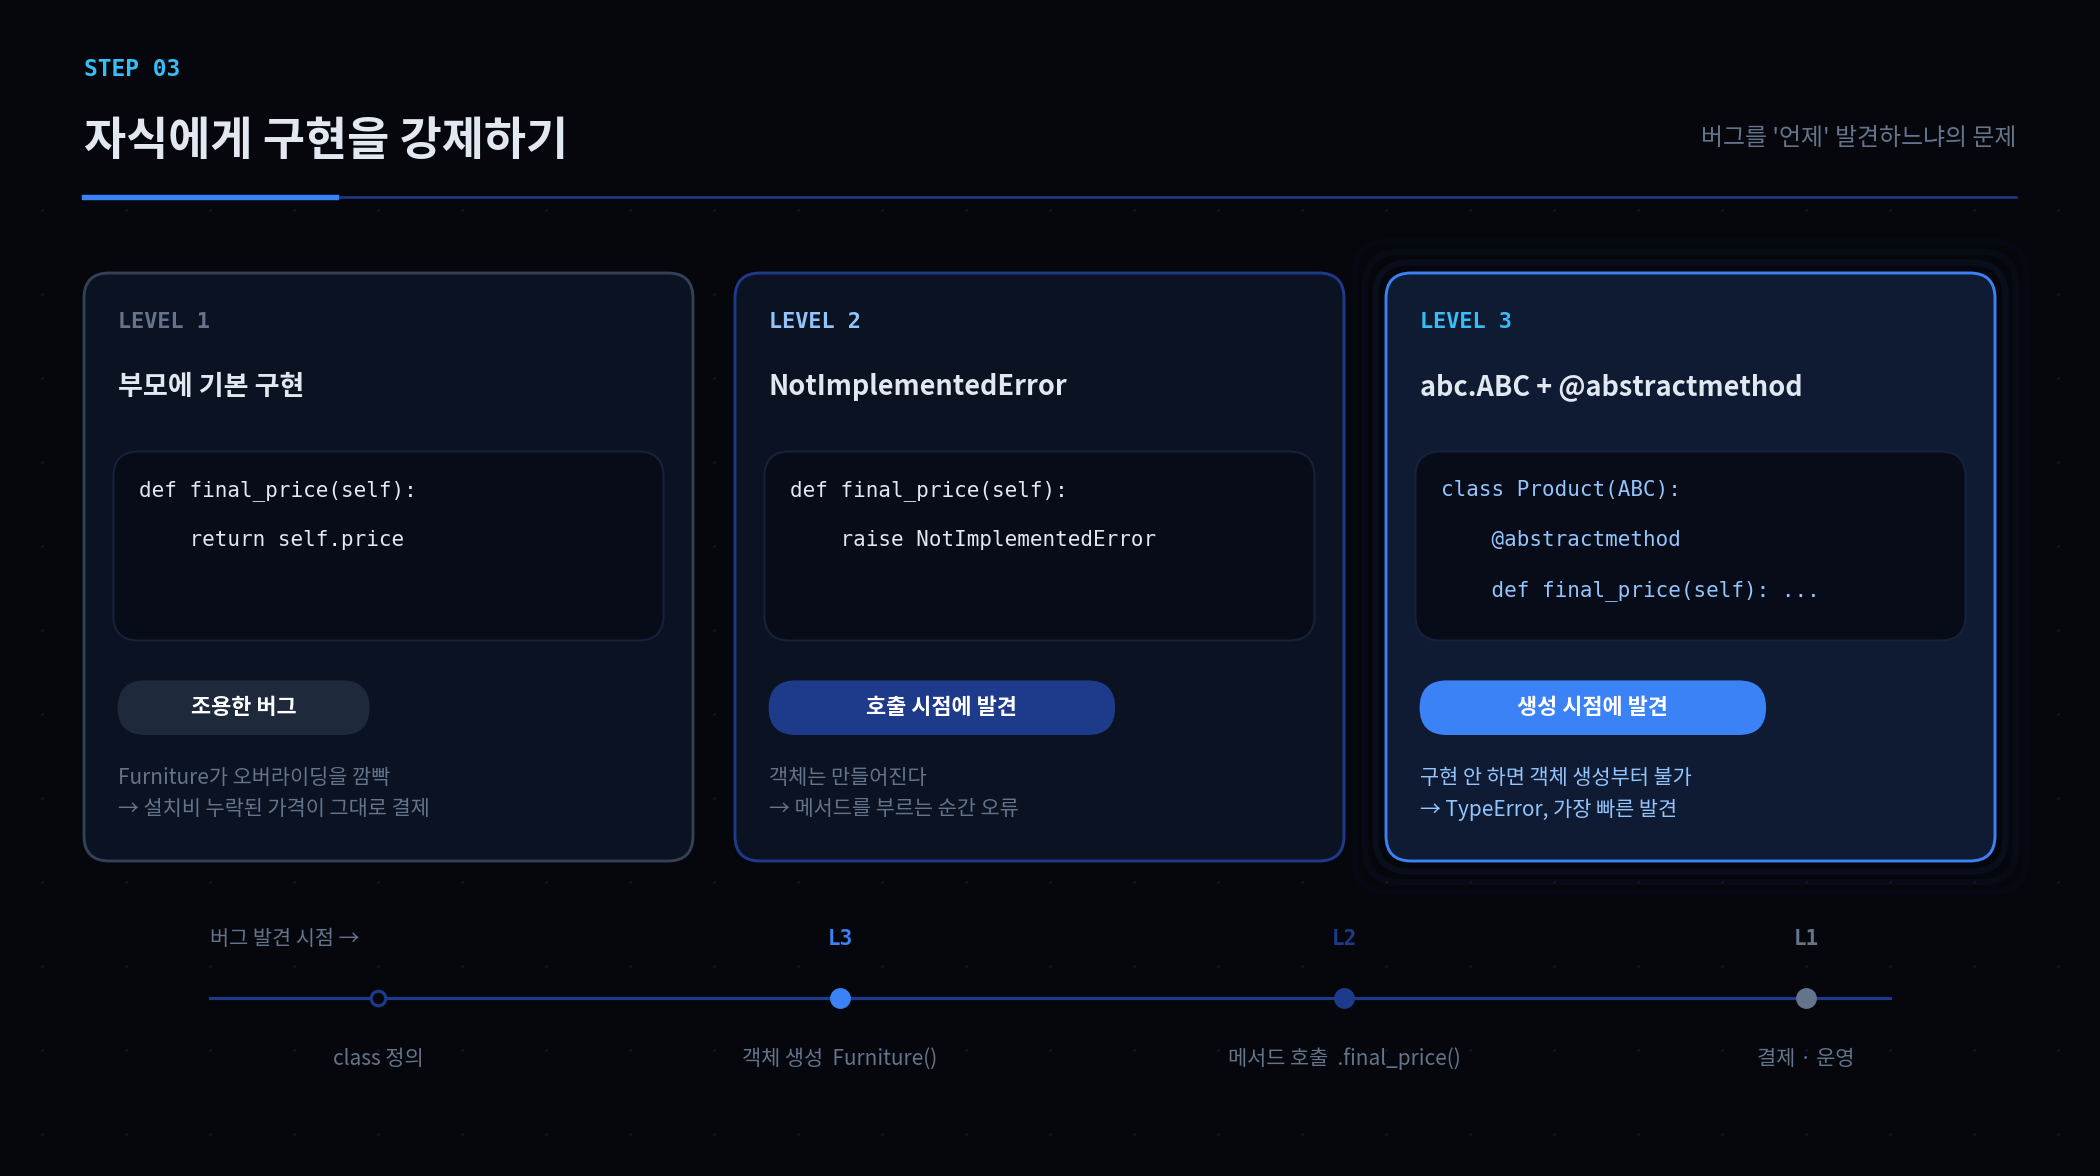

핵심 질문은 **버그를 언제 발견하느냐** 입니다. 빠를수록 좋습니다.

### LEVEL 2 · `NotImplementedError` — 호출하는 순간 알려 주기

부모 메서드에 기본값 대신 `raise NotImplementedError` 를 넣습니다.
"이 메서드는 자식이 반드시 구현해야 한다"는 **관례적인 표시**입니다.

In [ ]:
class ProductV2:
    category = "기타"

    def __init__(self, name, price):
        self.name = name
        self.price = price

    def final_price(self):
        raise NotImplementedError(f"{type(self).__name__} 은(는) final_price() 를 구현해야 합니다")

    def shipping_info(self):
        raise NotImplementedError(f"{type(self).__name__} 은(는) shipping_info() 를 구현해야 합니다")


class FurnitureV2(ProductV2):
    category = "가구"

    def shipping_info(self):
        return "2인 설치 배송"
    # final_price 를 또 깜빡


desk = FurnitureV2("원목 책상", 350_000)    # 객체는 문제없이 만들어진다
print("객체 생성 성공:", desk.name)

try:
    desk.final_price()                     # 호출하는 순간 오류!
except NotImplementedError as e:
    print("NotImplementedError:", e)

조용한 버그보다는 낫지만 한계가 있습니다.
- 객체는 **만들어진다** → 그 메서드를 **실제로 호출하기 전까지는** 모른다.
- 거의 쓰이지 않는 메서드라면? 운영 중 특정 상황에서야 터질 수 있습니다.

### LEVEL 3 · `abc` 모듈 — 객체를 만드는 순간 막기

`abc`(Abstract Base Class) 모듈을 쓰면, 추상 메서드를 구현하지 않은 클래스는 **객체 생성 자체가 불가능**합니다.

| 도구 | 역할 |
|---|---|
| `ABC` | 이 클래스를 상속하면 추상 클래스가 된다 |
| `@abstractmethod` | "자식이 반드시 구현해야 하는 메서드" 표시 |

In [ ]:
from abc import ABC, abstractmethod


class Product(ABC):
    """캠퍼스몰 상품 — 추상 클래스 (최종 버전)"""
    category = "기타"

    def __init__(self, name, price):
        self.name = name
        self.price = price

    @abstractmethod
    def final_price(self):
        """최종 결제 금액을 반환한다"""

    @abstractmethod
    def shipping_info(self):
        """배송 방법을 반환한다"""


# 1) 추상 클래스 자체는 객체를 만들 수 없다
try:
    Product("이름 없는 상품", 1000)
except TypeError as e:
    print("TypeError:", e)


# 2) 구현을 깜빡한 자식도 객체를 만들 수 없다
class Furniture(Product):
    category = "가구"

    def shipping_info(self):
        return "2인 설치 배송"


try:
    Furniture("원목 책상", 350_000)
except TypeError as e:
    print("TypeError:", e)

이제 서연은 테스트를 돌리자마자 실수를 알아챕니다. 올바르게 고친 가구 클래스와, 새 추상 `Product` 를 상속하는 나머지 상품들을 다시 정의합니다.

In [ ]:
class Furniture(Product):
    category = "가구"

    def final_price(self):
        return self.price + 50_000

    def shipping_info(self):
        return "2인 설치 배송"


class Electronics(Product):
    category = "전자제품"
    def final_price(self):   return self.price + self.price * 5 // 100
    def shipping_info(self): return "설치 기사 방문"


class Clothing(Product):
    category = "의류"
    def final_price(self):   return self.price * 80 // 100
    def shipping_info(self): return "일반 택배"      # 이제는 반드시 직접 써야 한다


class Food(Product):
    category = "식품"
    def final_price(self):   return self.price + 3000
    def shipping_info(self): return "새벽 냉장 배송"


class Book(Product):
    category = "도서"
    def final_price(self):   return self.price * 90 // 100
    def shipping_info(self): return "무료 배송"


desk = Furniture("원목 책상", 350_000)
print(f"{desk.name} 결제 금액: {desk.final_price():,}원")

### 정리: 세 가지 방법 비교

| | 부모 기본 구현 | `NotImplementedError` | `abc.ABC` + `@abstractmethod` |
|---|---|---|---|
| 구현 깜빡 시 | 조용히 잘못된 값 | 호출할 때 오류 | **객체 생성할 때** 오류 |
| 발견 시점 | 운영 중 (최악) | 실행 중 | 가장 빠름 |
| 부모 객체 생성 | 가능 | 가능 | **불가능** |
| 쓰임새 | 대부분의 자식이 같은 동작을 공유할 때 | 가벼운 관례, 오래된 코드 | 반드시 지켜야 할 **설계 규약** |

## 실습 3-1 · 할인 정책 추상 클래스 만들기

캠퍼스몰 마케팅팀이 여러 가지 **할인 쿠폰**을 만들려고 합니다. 다형성으로 설계하세요.

1. 추상 클래스 `Discount(ABC)` : 추상 메서드 `apply(self, price)` (할인 적용 후 가격 반환)
2. `RateDiscount(rate)` : 정률 할인. `RateDiscount(10).apply(50_000)` → `45_000` (`price * (100 - rate) // 100`)
3. `AmountDiscount(amount)` : 정액 할인. `AmountDiscount(5_000).apply(50_000)` → `45_000`
   단, 결과가 0보다 작아지면 `0` 을 반환 (`max(0, ...)`)

In [ ]:
from abc import ABC, abstractmethod


class Discount(ABC):
    # TODO: 추상 메서드 apply(self, price) 선언
    pass


class RateDiscount(Discount):
    def __init__(self, rate):
        self.rate = rate

    # TODO: apply 구현


class AmountDiscount(Discount):
    def __init__(self, amount):
        self.amount = amount

    # TODO: apply 구현

In [ ]:
# 확인 셀 — 여러 쿠폰을 리스트에 담아 for 문 하나로 비교
coupons = [RateDiscount(10), AmountDiscount(5_000), AmountDiscount(100_000)]
for c in coupons:
    print(f"{type(c).__name__:15} → {c.apply(50_000):,}원")

assert RateDiscount(10).apply(50_000) == 45_000
assert AmountDiscount(5_000).apply(50_000) == 45_000
assert AmountDiscount(100_000).apply(50_000) == 0

try:
    Discount()
    raise AssertionError("Discount 는 객체를 만들 수 없어야 합니다")
except TypeError:
    pass
print("\n실습 3-1 통과!")

---
# STEP 4 · 덕 타이핑 — 족보보다 능력

> 캠퍼스몰이 외부 파트너사와 제휴했습니다. 파트너사가 보내 준 **기프트카드** 클래스는 우리 `Product` 를 **상속하지 않습니다.**
> 남의 회사 코드라 고칠 수도 없습니다. 장바구니에 넣을 수 있을까요?

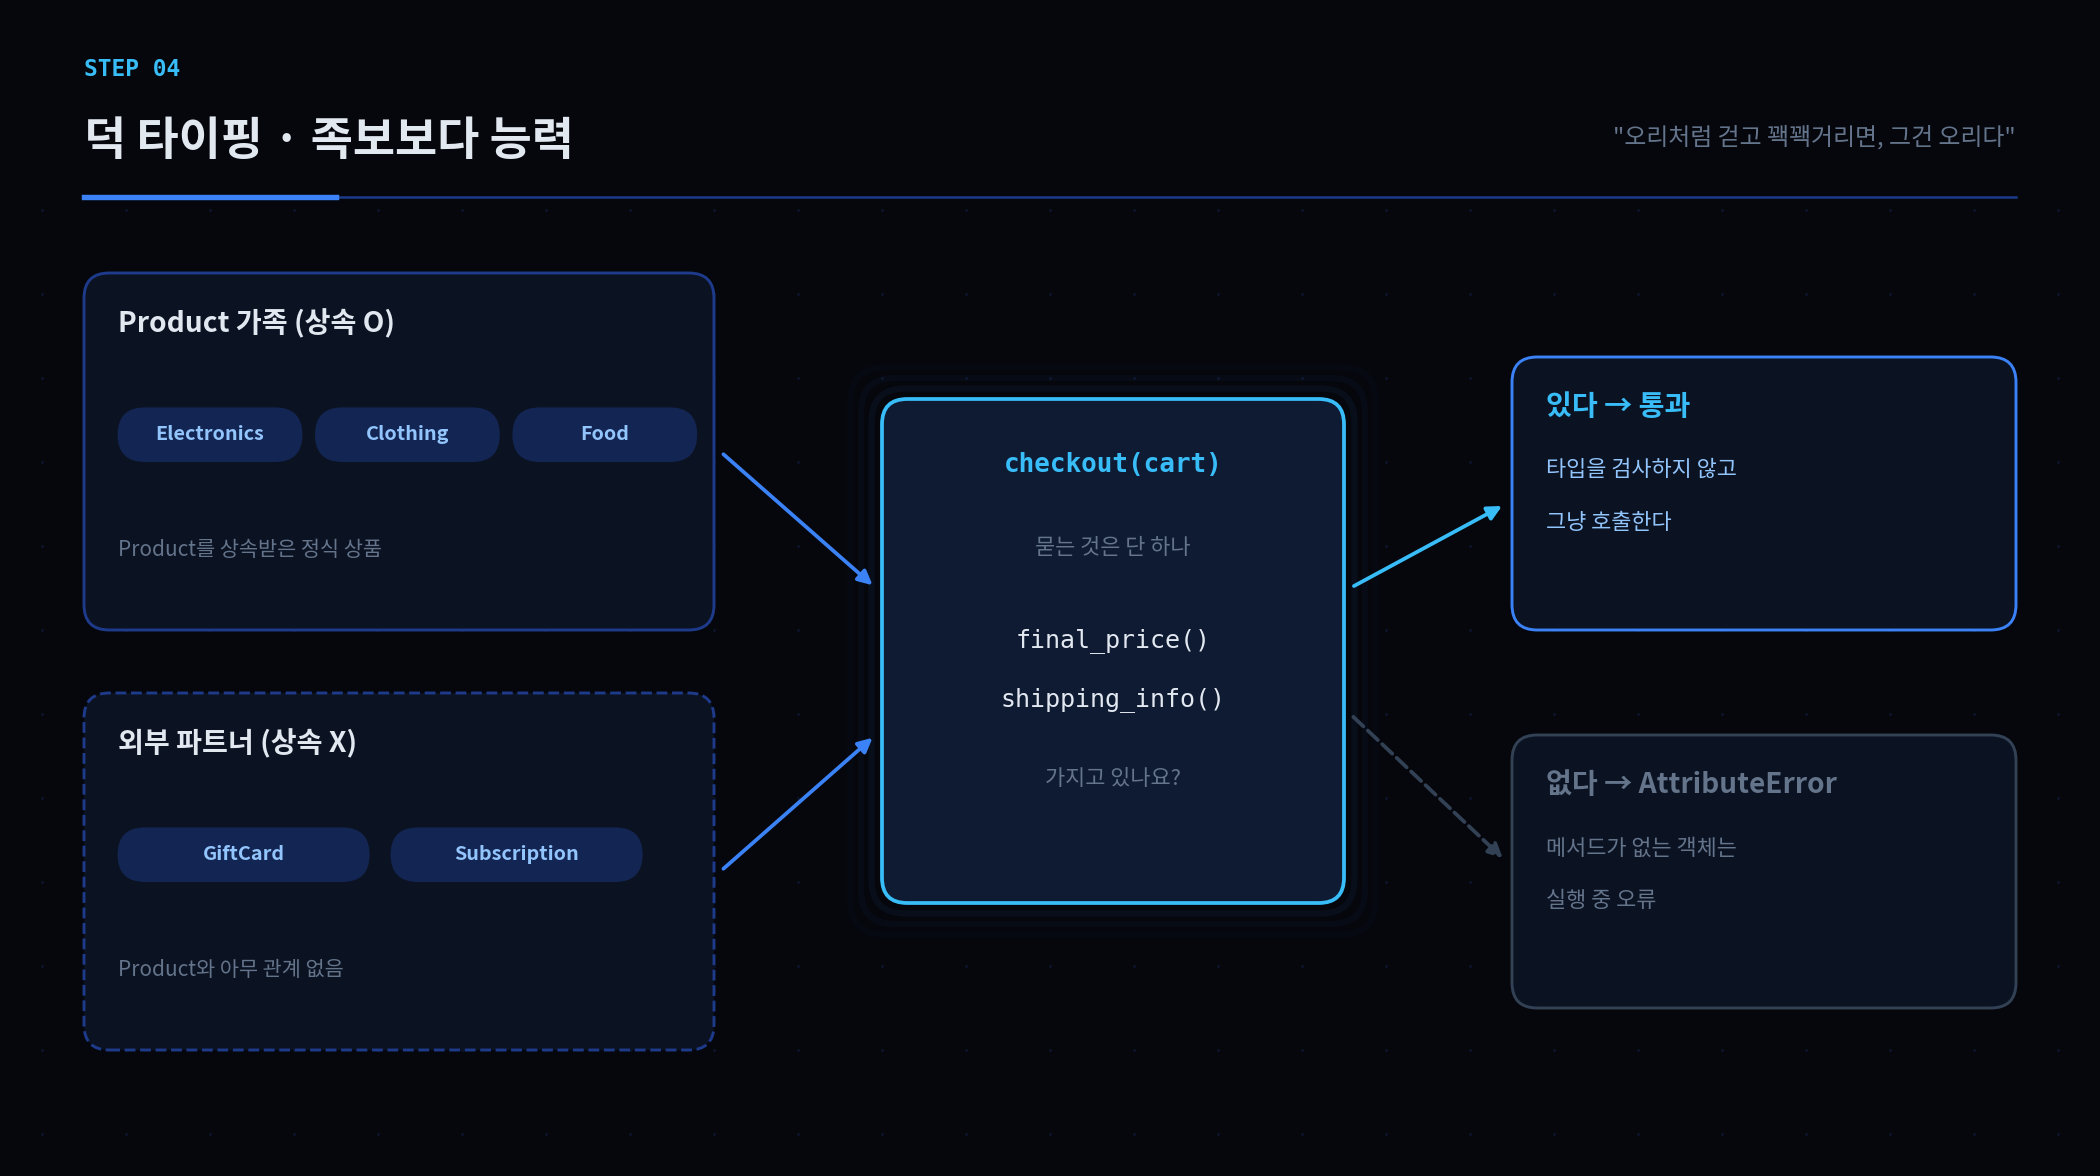

> **"오리처럼 걷고, 오리처럼 꽥꽥거리면, 그것은 오리다."**
>
> 파이썬은 객체가 **어떤 클래스인지(족보)** 보다 **필요한 메서드를 가지고 있는지(능력)** 를 봅니다.
> 이것을 **덕 타이핑(duck typing)** 이라고 합니다.

In [ ]:
def checkout(cart):
    """장바구니 결제 — item 의 타입을 전혀 검사하지 않는다"""
    total = 0
    for item in cart:
        p = item.final_price()
        total += p
        print(f"{item.name:8} {p:>10,}원  | {item.shipping_info()}")
    print(f"합계: {total:,}원")
    return total


# 외부 파트너사가 만든 클래스 (Product 상속 X)
class GiftCard:
    def __init__(self, name, amount):
        self.name = name
        self.amount = amount

    def final_price(self):
        return self.amount

    def shipping_info(self):
        return "이메일 발송"


cart = [
    Electronics("노트북", 1_200_000),
    Clothing("후드티", 89_000),
    GiftCard("기프트카드", 50_000),     # 족보가 다른 객체도 함께!
]
checkout(cart)

gift = cart[-1]
print("\nGiftCard 는 Product 인가?", isinstance(gift, Product))

### 능력이 없으면? → `AttributeError`

덕 타이핑은 **실행 시점에** 메서드를 찾습니다. 필요한 메서드가 없으면 그때 오류가 납니다.

In [ ]:
class Pen:                     # 상품처럼 생겼지만 final_price 가 없다
    def __init__(self, name):
        self.name = name


try:
    checkout([Pen("볼펜")])
except AttributeError as e:
    print("AttributeError:", e)

### 미리 확인하고 싶다면: `hasattr()`

파이썬에서는 보통 **"일단 시도하고, 실패하면 처리"(EAFP)** 방식을 선호하지만,
필요하면 `hasattr()` 로 능력을 미리 확인할 수 있습니다.

In [ ]:
def can_checkout(obj):
    return hasattr(obj, "final_price") and hasattr(obj, "shipping_info")


for obj in [Electronics("모니터", 300_000), GiftCard("기프트카드", 30_000), Pen("볼펜")]:
    print(f"{type(obj).__name__:12} 결제 가능? {can_checkout(obj)}")

### 상속 다형성 vs 덕 타이핑

| | 상속 기반 다형성 (STEP 2~3) | 덕 타이핑 (STEP 4) |
|---|---|---|
| 조건 | 같은 부모를 상속 | 같은 이름의 메서드만 있으면 됨 |
| 장점 | `abc` 로 구현을 강제, 구조가 명확 | 남의 코드·외부 라이브러리도 그대로 수용 |
| 단점 | 수정할 수 없는 외부 클래스는 편입 어려움 | 메서드 누락을 실행 전에 잡기 어려움 |
| 파이썬 예 | 직접 설계한 클래스 계층 | `len()` 은 `__len__` 만 있으면 동작 |

## 실습 4-1 · 구독 서비스를 장바구니에 넣기

캠퍼스몰이 **월 구독 서비스**(예: 프리미엄 멤버십)를 판매합니다. `Product` 를 **상속하지 말고** 클래스를 만드세요.

- 클래스 이름: `Subscription`
- 생성자: `name`, `monthly_fee`, `months`
- `final_price()`: `monthly_fee × months`
- `shipping_info()`: `"배송 없음 (디지털)"`

만든 뒤 `checkout()` 을 **수정하지 않고** 장바구니에 넣어 결제하세요.

In [ ]:
class Subscription:
    # TODO: __init__, final_price, shipping_info 구현
    pass


cart = [
    Book("파이썬 입문", 30_000),
    GiftCard("기프트카드", 50_000),
    # TODO: Subscription("프리미엄 멤버십", 9_900, 12) 추가
]
total = checkout(cart)

In [ ]:
# 확인 셀
s = Subscription("프리미엄 멤버십", 9_900, 12)
assert s.final_price() == 118_800
assert s.shipping_info() == "배송 없음 (디지털)"
assert not isinstance(s, Product)
assert total == 27_000 + 50_000 + 118_800
print("실습 4-1 통과!")

---
# STEP 5 · `__str__` — 객체의 얼굴 바꾸기

> 결제 기능이 완성되고, 민준은 영수증 출력 기능을 만들다가 이상한 화면을 봅니다.

In [ ]:
laptop = Electronics("노트북", 1_200_000)
print(laptop)

`<__main__.Electronics object at 0x...>` — 클래스 이름과 메모리 주소뿐입니다. 고객 영수증에 이걸 찍을 수는 없죠.

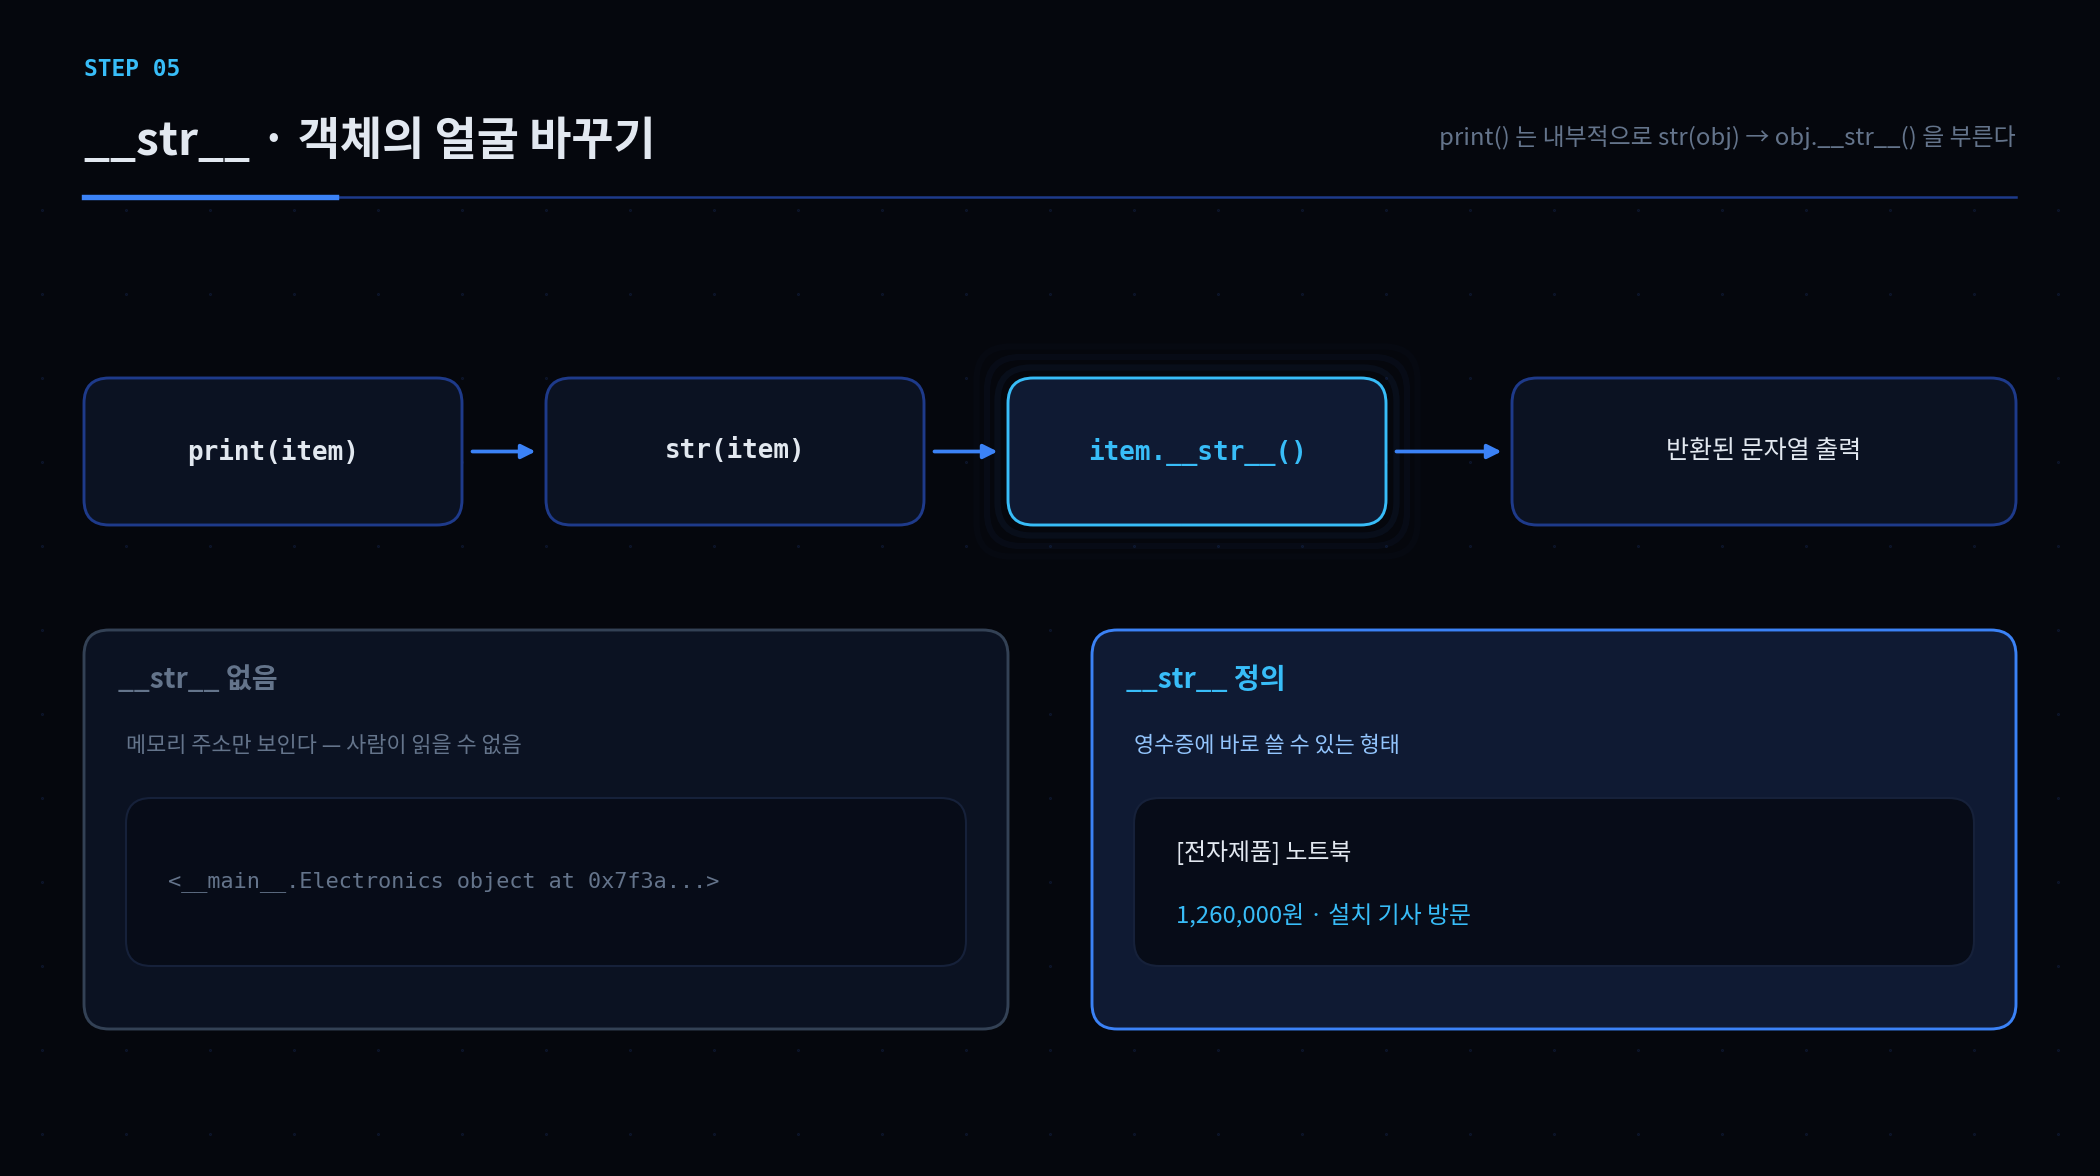

`print(obj)` 는 내부적으로 `str(obj)` 를 부르고, `str(obj)` 는 **`obj.__str__()`** 를 부릅니다.
그러니 `__str__` 을 정의하면 객체가 출력되는 모습을 우리가 정할 수 있습니다.

> `__str__` 은 반드시 **문자열을 반환(return)** 해야 합니다. `print` 를 하면 안 됩니다.

그리고 여기서도 **다형성**이 일어납니다. `print()` 라는 하나의 명령에, 객체마다 자기 `__str__` 로 응답합니다.

### 부모 클래스에 `__str__` 을 한 번만 정의

`__str__` 안에서 `self.final_price()` 를 부르면, 자식마다 **자기의** `final_price()` 가 호출됩니다.
부모에 한 번만 써도 모든 자식이 올바르게 출력됩니다.

In [ ]:
from abc import ABC, abstractmethod


class Product(ABC):
    category = "기타"

    def __init__(self, name, price):
        self.name = name
        self.price = price

    @abstractmethod
    def final_price(self): ...

    @abstractmethod
    def shipping_info(self): ...

    def __str__(self):                                   # 새로 추가
        return (f"[{self.category}] {self.name} | "
                f"{self.final_price():,}원 · {self.shipping_info()}")


class Electronics(Product):
    category = "전자제품"
    def final_price(self):   return self.price + self.price * 5 // 100
    def shipping_info(self): return "설치 기사 방문"


class Clothing(Product):
    category = "의류"
    def final_price(self):   return self.price * 80 // 100
    def shipping_info(self): return "일반 택배"


class Food(Product):
    category = "식품"
    def final_price(self):   return self.price + 3000
    def shipping_info(self): return "새벽 냉장 배송"


class Book(Product):
    category = "도서"
    def final_price(self):   return self.price * 90 // 100
    def shipping_info(self): return "무료 배송"


class Furniture(Product):
    category = "가구"
    def final_price(self):   return self.price + 50_000
    def shipping_info(self): return "2인 설치 배송"


cart = [
    Electronics("노트북", 1_200_000),
    Clothing("후드티", 89_000),
    Food("감귤박스", 25_000),
    Book("파이썬 입문", 30_000),
    Furniture("원목 책상", 350_000),
]
for item in cart:
    print(item)                     # print 하나, 출력 형태는 각자

### `str()` 과 f-string 도 같은 `__str__` 을 쓴다

In [ ]:
laptop = Electronics("노트북", 1_200_000)
s = str(laptop)
print(type(s), s)
print(f"오늘의 추천: {laptop}")

### 참고: `__repr__` 은?

리스트를 통째로 출력하면 원소는 `__str__` 이 아니라 `__repr__` 로 표시됩니다.
`__repr__` 은 **개발자용** 표현(디버깅용)이고, `__str__` 은 **사용자용** 표현입니다.

In [ ]:
print(cart[:2])        # 리스트 안의 객체는 __repr__ 로 표시된다

## 실습 5-1 · 기프트카드와 구독에도 얼굴 달아 주기

STEP 4의 `GiftCard`, `Subscription` 은 `Product` 를 상속하지 않으므로 `__str__` 을 물려받지 못합니다.
각각 `__str__` 을 추가해서 아래처럼 출력되게 만드세요.

```
[기프트카드] 기프트카드 | 50,000원 · 이메일 발송
[구독] 프리미엄 멤버십 (12개월) | 118,800원 · 배송 없음 (디지털)
```

In [ ]:
class GiftCard:
    def __init__(self, name, amount):
        self.name = name
        self.amount = amount

    def final_price(self):
        return self.amount

    def shipping_info(self):
        return "이메일 발송"

    # TODO: __str__ 구현


class Subscription:
    def __init__(self, name, monthly_fee, months):
        self.name = name
        self.monthly_fee = monthly_fee
        self.months = months

    def final_price(self):
        return self.monthly_fee * self.months

    def shipping_info(self):
        return "배송 없음 (디지털)"

    # TODO: __str__ 구현

In [ ]:
# 확인 셀
g = GiftCard("기프트카드", 50_000)
s = Subscription("프리미엄 멤버십", 9_900, 12)
print(g)
print(s)
assert str(g) == "[기프트카드] 기프트카드 | 50,000원 · 이메일 발송"
assert str(s) == "[구독] 프리미엄 멤버십 (12개월) | 118,800원 · 배송 없음 (디지털)"
print("\n실습 5-1 통과!")

---
# 최종 미션 · 주문 영수증 시스템

> 출시 전날, 팀장님의 마지막 요청입니다.
> *"주문 한 건을 객체로 만들고, `print(order)` 하면 영수증이 나오게 해 줘. 쿠폰도 적용돼야 해."*

오늘 배운 다섯 가지를 모두 사용합니다.

| 요구사항 | 사용하는 개념 |
|---|---|
| 상품 종류를 묻지 않고 합계 계산 | 다형성, 리스트 + for |
| `Product` 가 아닌 `GiftCard`, `Subscription` 도 담기 | 덕 타이핑 |
| 쿠폰은 `Discount` 의 어떤 자식이든 적용 | `abc` 추상 클래스 (실습 3-1) |
| `print(order)` 로 영수증 출력 | `__str__` |

### `Order` 클래스 명세
- `__init__(self, customer)` : 고객 이름 저장, 빈 상품 리스트, 쿠폰은 `None`
- `add(self, item)` : 상품 추가
- `set_coupon(self, coupon)` : 쿠폰 지정
- `subtotal(self)` : 모든 상품의 `final_price()` 합계
- `total(self)` : 쿠폰이 있으면 `coupon.apply(subtotal)`, 없으면 `subtotal`
- `__str__(self)` : 아래 형식의 영수증 문자열 반환 (각 상품 줄은 **상품의 `str()`** 을 그대로 사용)

```
===== 캠퍼스몰 영수증 =====
고객: 민준
 1. [전자제품] 노트북 | 1,260,000원 · 설치 기사 방문
 2. [도서] 파이썬 입문 | 27,000원 · 무료 배송
 3. [기프트카드] 기프트카드 | 50,000원 · 이메일 발송
---------------------------
소계: 1,337,000원
할인: -133,700원
합계: 1,203,300원
```

힌트: 줄 목록을 리스트에 모은 뒤 `"\n".join(lines)` 로 합치세요.

In [ ]:
class Order:
    def __init__(self, customer):
        # TODO
        pass

    def add(self, item):
        # TODO
        pass

    def set_coupon(self, coupon):
        # TODO
        pass

    def subtotal(self):
        # TODO
        pass

    def total(self):
        # TODO
        pass

    def __str__(self):
        # TODO: 영수증 문자열 만들어 return
        pass

In [ ]:
# 확인 셀
order = Order("민준")
order.add(Electronics("노트북", 1_200_000))
order.add(Book("파이썬 입문", 30_000))
order.add(GiftCard("기프트카드", 50_000))
order.set_coupon(RateDiscount(10))

print(order)

assert order.subtotal() == 1_337_000
assert order.total() == 1_203_300
assert "1. [전자제품] 노트북" in str(order)

order2 = Order("서연")
order2.add(Furniture("원목 책상", 350_000))
order2.add(Subscription("프리미엄 멤버십", 9_900, 12))
order2.set_coupon(AmountDiscount(20_000))
print()
print(order2)
assert order2.total() == 400_000 + 118_800 - 20_000
print("\n최종 미션 통과! 캠퍼스몰 출시 준비 완료.")

---
# 정리

| 학습 목표 | 한 줄 요약 | 오늘의 코드 |
|---|---|---|
| 다형성 | **하나의 명령, 여러 결과** — 같은 메서드 호출이 객체마다 다르게 동작 | `item.final_price()` |
| if/elif 리팩터링 | 분기를 없애고 각 클래스 안으로 옮긴다 | `class Book(Product)` |
| 리스트 + for | 종류가 섞인 객체도 for 문 하나로 처리 | `for item in cart:` |
| 구현 강제 | `NotImplementedError` 는 호출 시, `abc` 는 생성 시 오류 | `@abstractmethod` |
| 덕 타이핑 | 상속(족보)이 아니라 메서드(능력)를 본다 | `GiftCard`, `Subscription` |
| `__str__` | `print()` / `str()` 이 보여 줄 문자열을 정한다 | `def __str__(self): return ...` |

### 확인 퀴즈
1. 다형성을 "하나의 명령, 여러 결과"를 사용해 한 문장으로 설명하세요.
2. STEP 2에서 도서를 추가할 때, 장바구니 for 문을 수정해야 했나요? 그 이유는?
3. `NotImplementedError` 방식과 `abc` 방식은 오류가 **언제** 나는지가 어떻게 다른가요?
4. `GiftCard` 는 `Product` 가 아닌데 `checkout()` 에서 동작한 이유는?
5. `__str__` 안에서 `print()` 만 하고 `return` 하지 않으면 어떻게 되나요?